# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Bassez 2021's malignant manifold is **non-branching**: the three embryonic signatures resolve
into a single **posterior-somitogenesis → neural-crest** gradient (pSom & Crest strongly
anti-correlated, r≈−0.82 smoothed), with gastrulation weak and flat — *not* a Gast/pSom hub
radiating into two competing arms. A PPT **tree** fit as an honest branching test places **every
tip at negative Gast** with no Gast-high arm, i.e. the tree's forks are lobe over-fitting, not a
developmental bifurcation. The correct topology is therefore a **principal curve** (ElPiGraph,
non-branching by construction) on the *joint* embedding — no re-embedding (re-embedding an
elongated compartment fabricates folds). Cycling is low and orthogonal to the axis, so the whole
manifold is kept (no scoping). Root at the pSom-high / Crest-low developmental origin; Crest is
**late**. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [2]:
import os, sys, glob, re, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [3]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Cells stay on their joint embedding — no re-embedding. The three embryonic signatures are scored
against the shared **union** control pool and graph-smoothed (kNN averaging) to read geography
rather than 10x per-cell dropout.

In [5]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c0 = xy - xy.mean(0)
from numpy.linalg import svd
_,s,_ = svd(c0, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('global raw means:', {k: round(float(adata.obs[k].mean()),4) for k in ['Gast','pSom','Crest']})

whole malignant manifold: 65802 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.13
Gast: 78/81 genes present
pSom: 93/98 genes present
Crest: 104/104 genes present
global raw means: {'Gast': -0.0136, 'pSom': 0.0221, 'Crest': -0.005}


### Scope decision — whole manifold vs a sub-lobe (data-driven)
Test whether the developmental axis is confined to one lobe (Kürten case → scope) or spans the
manifold (Bischoff/Sun case → keep whole). Two facts settle it: (i) cycling is low across all
lobes so there is no cycling lobe to exclude; (ii) the smoothed developmental signatures form a
single pSom↔Crest axis distributed across the manifold. Keep the whole manifold.

In [7]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.3f}')
print('\nper-lobe smoothed developmental means:')
print(adata.obs.groupby('lobe', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
print('\nper-lobe cycling fraction:', adata.obs.groupby('lobe',observed=True)['cycling'].mean().round(3).to_dict())
print('-> cycling low & uniform; single pSom<->Crest axis -> keep whole manifold (no scoping).')
sub = adata

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.213
  Crest_sm vs Gast_sm: r = -0.241
  Crest_sm vs pSom_sm: r = -0.822

per-lobe smoothed developmental means:
      Gast_sm  pSom_sm  Crest_sm
lobe                            
0     -0.0151   0.0122    0.0046
1     -0.0154   0.0099    0.0056
2     -0.0102   0.0427   -0.0248
3     -0.0210   0.0202    0.0020
4     -0.0133   0.0228   -0.0051
5     -0.0110   0.0097   -0.0013
6     -0.0016   0.0292   -0.0148

per-lobe cycling fraction: {'0': 0.038, '1': 0.02, '2': 0.01, '3': 0.022, '4': 0.052, '5': 0.008, '6': 0.018}
-> cycling low & uniform; single pSom<->Crest axis -> keep whole manifold (no scoping).


### Honest branching test — fit a PPT tree and inspect the tips
Per the binding protocol we test branching honestly before committing to a curve. A genuine
bifurcation would place one tip at high Gast and another at high pSom (the cross-repression
arms). Here **all tips are Gast-negative** and differ only in the pSom↔Crest trade-off — no
Gast arm exists, so the tree's forks are lobe over-fitting on a single-axis manifold. The
non-branching curve is the correct object.

In [9]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(sub, method='ppt', Nodes=200, ppt_lambda=2000, ppt_sigma=0.5,
                use_rep='X_umap', seed=SEED, plot=False)
B = np.asarray(sub.uns['graph']['B']); deg = (B>0).sum(0)
tips = np.where(deg==1)[0]; forks = int((deg>=3).sum())
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
print(f'PPT tree: {len(tips)} tips, {forks} forks (branch nodes)')
print('tip signature means (cells within 3 nodes) — Gast is negative at EVERY tip:')
gmax = -1e9
for tp in tips:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    if m.sum()==0: continue
    gm,pm,cm = sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean()
    gmax = max(gmax, gm)
    print(f'  tip {tp:3d}: n={m.sum():5d}  Gast={gm:+.4f}  pSom={pm:+.4f}  Crest={cm:+.4f}')
print(f'max tip Gast = {gmax:+.4f} (<0): no Gast-high arm -> forks are lobe over-fitting, not a bifurcation')

PPT tree: 11 tips, 9 forks (branch nodes)
tip signature means (cells within 3 nodes) — Gast is negative at EVERY tip:
  tip   7: n= 1916  Gast=-0.0138  pSom=+0.0206  Crest=-0.0025
  tip  22: n= 2229  Gast=-0.0171  pSom=+0.0161  Crest=+0.0009
  tip  23: n= 2184  Gast=-0.0381  pSom=+0.0400  Crest=-0.0020
  tip  26: n= 2440  Gast=-0.0134  pSom=+0.0302  Crest=-0.0113
  tip  30: n= 1671  Gast=-0.0175  pSom=+0.0090  Crest=+0.0080
  tip  82: n= 1513  Gast=-0.0145  pSom=+0.0087  Crest=+0.0055
  tip  99: n= 1890  Gast=-0.0179  pSom=+0.0172  Crest=+0.0051
  tip 114: n= 2172  Gast=-0.0081  pSom=+0.0477  Crest=-0.0363
  tip 118: n= 1964  Gast=-0.0212  pSom=+0.0551  Crest=-0.0165
  tip 139: n= 1715  Gast=-0.0100  pSom=+0.0051  Crest=-0.0001
  tip 145: n= 2334  Gast=-0.0015  pSom=+0.0329  Crest=-0.0173
max tip Gast = -0.0015 (<0): no Gast-high arm -> forks are lobe over-fitting, not a bifurcation


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone. A node self-approach ratio > 1
(minimum distance between graph-non-adjacent nodes, in units of median edge length) certifies the
curve does not fold back on itself; `epg_mu=100` keeps the arc smooth. Fold-freedom is verified
off the graph geometry, not off a metric that reads neighbours from the embedding under test.

In [11]:
def fold_diag(a):
    B = np.asarray(a.uns['graph']['B']); F = a.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for x in range(F.shape[0]):
        for y in range(x+1, F.shape[0]):
            if G[x,y] >= 3: dmin = min(dmin, np.sqrt(((F[x]-F[y])**2).sum()))
    t_ = int(((B>0).sum(0)==1).sum()); f_ = int(((B>0).sum(0)>=3).sum())
    return dmin/med, t_, f_
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, t_, f_ = fold_diag(sub)
print(f'curve: {t_} tips, {f_} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert f_ == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.43 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where pSom is highest and Crest lowest — the developmental origin.
Pseudotime then flows to the neural-crest terminus (Crest is late).

In [13]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(pSom-high, Crest-low origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')
print('-> pSom declines, Crest rises (terminal); cycling co-varies weakly -> axis is developmental')

tip 0: Gast=-0.0150 pSom=+0.0121 Crest=+0.0046
tip 2: Gast=-0.0154 pSom=+0.0234 Crest=-0.0035
derived root = tip 2 (pSom-high, Crest-low origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.090 p=1.2e-117
  pSom_sm: rho=-0.309 p=0.0e+00
  Crest_sm: rho=+0.304 p=0.0e+00
  cyc_score: rho=+0.178 p=0.0e+00
-> pSom declines, Crest rises (terminal); cycling co-varies weakly -> axis is developmental


### Reorient to house style (pseudotime left → right)
Orient using only raw UMAP coordinates (discrete axis pick + sign flip, no rotation — a rotation
could silently reflect an axis). The assertion confirms low pseudotime lands on the left.

In [15]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
rx = abs(np.corrcoef(xy[:,0], t)[0,1]); ry = abs(np.corrcoef(xy[:,1], t)[0,1])
xyr = xy.copy() if rx >= ry else xy[:, ::-1].copy()   # put the more pseudotime-aligned axis on x
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0: xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: corr(x_lin, pseudotime) = {r:+.2f}')

orientation: corr(x_lin, pseudotime) = +0.78


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


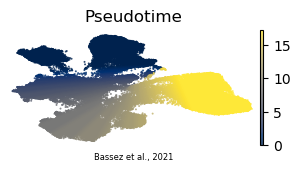

In [17]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=8, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')